<a href="https://colab.research.google.com/github/adytriaby/PCVK_Ganjil2026/blob/main/week7_pcvk.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Week 7 — Segmentasi Citra dengan Thresholding
### Pengolahan Citra dan Visi Komputer

**Nama:** Adytria Bayu Ramadani
**NIM:** 254107023004
**Kelas:** TI3E


## 0. Setup

Import library dan pengaturan tampilan. `google.colab` dibungkus `try/except` agar notebook tetap bisa diuji di luar Colab.

In [ ]:
import os
import math
import random
from collections import deque

import cv2
import numpy as np
import matplotlib.pyplot as plt
from sklearn.cluster import KMeans

try:
    from google.colab import files
    IN_COLAB = True
except ImportError:
    IN_COLAB = False

plt.rcParams["figure.dpi"] = 110
plt.rcParams["image.cmap"] = "gray"
np.random.seed(42)
random.seed(42)

print("OpenCV  :", cv2.__version__)
print("NumPy   :", np.__version__)
print("Colab   :", IN_COLAB)

OpenCV  : 5.0.0
NumPy   : 2.1.3
Colab   : True


### Upload citra

Dua foto tugas diupload manual: `ktp1_fulan.jpg` (Tugas 1) dan `ktp2_fulani.jpg` (Tugas 2). Jika nama file berbeda, notebook otomatis memakai file gambar pertama yang diupload.

In [ ]:
DAFTAR_FILE = ["ktp1_fulan.jpg", "ktp2_fulani.jpg"]

hilang = [nama for nama in DAFTAR_FILE if not os.path.exists(nama)]
if hilang:
    if IN_COLAB:
        print("File yang belum ada:", ", ".join(hilang))
        print("Silakan upload kedua foto KTP sekarang:")
        uploaded = files.upload()
        kandidat = [
            n for n in uploaded
            if n.lower().endswith((".jpg", ".jpeg", ".png")) and n not in DAFTAR_FILE
        ]
        for nama in hilang:
            if nama in uploaded:
                continue
            if not kandidat:
                raise FileNotFoundError(f"File '{nama}' tidak ditemukan pada hasil upload.")
            os.rename(kandidat.pop(0), nama)
    else:
        raise FileNotFoundError(
            "Letakkan " + " dan ".join(hilang) + " di folder yang sama dengan notebook ini."
        )


def muat_citra(nama):
    citra = cv2.imread(nama)
    if citra is None:
        raise ValueError(f"'{nama}' tidak bisa dibaca sebagai citra.")
    return citra


ktp1_bgr = muat_citra(DAFTAR_FILE[0])
ktp2_bgr = muat_citra(DAFTAR_FILE[1])

ktp1_rgb = cv2.cvtColor(ktp1_bgr, cv2.COLOR_BGR2RGB)
ktp2_rgb = cv2.cvtColor(ktp2_bgr, cv2.COLOR_BGR2RGB)
ktp1_gray = cv2.cvtColor(ktp1_bgr, cv2.COLOR_BGR2GRAY)
ktp2_gray = cv2.cvtColor(ktp2_bgr, cv2.COLOR_BGR2GRAY)

for nama, citra in [(DAFTAR_FILE[0], ktp1_rgb), (DAFTAR_FILE[1], ktp2_rgb)]:
    print(f"{nama:18s} shape={citra.shape}  mean={citra.mean():6.1f}  min={citra.min()}  max={citra.max()}")

File yang belum ada: ktp2_fulani.jpg
Silakan upload kedua foto KTP sekarang:


Saving ktp2_fulani.jpg to ktp2_fulani.jpg
ktp1_fulan.jpg     shape=(458, 694, 3)  mean= 209.1  min=0  max=255
ktp2_fulani.jpg    shape=(400, 634, 3)  mean= 154.9  min=0  max=255


### Fungsi bantu: tampilan, histogram, dan metrik

Metrik yang dipakai sepanjang notebook:

- **IoU (Intersection over Union)** dan **Dice** → mengukur tumpang tindih mask hasil segmentasi dengan *ground truth*.
- **Presisi / Recall** → presisi tinggi berarti sedikit piksel latar yang ikut masuk objek; recall tinggi berarti objek tidak banyak yang hilang.
- **Rasio tinta** → persentase piksel yang dianggap objek; berguna membandingkan mask tanpa *ground truth*.

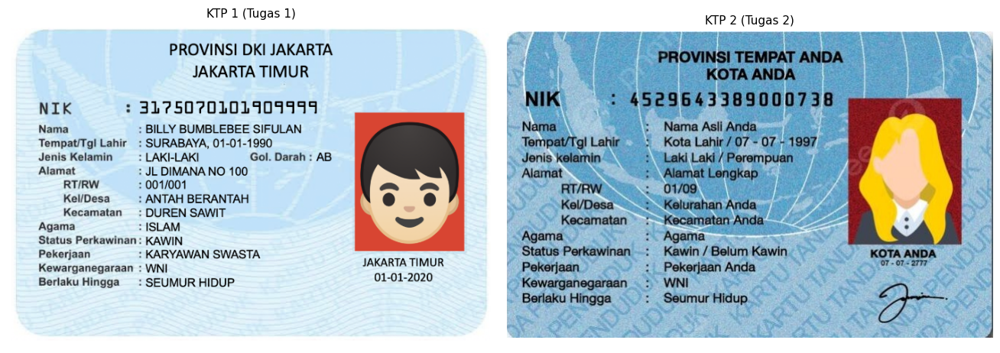

In [ ]:
def tampilkan(daftar_citra, judul=None, cmap="gray", ncols=None, skala=4.2):
    """Menampilkan satu atau beberapa citra dalam grid."""
    if not isinstance(daftar_citra, (list, tuple)):
        daftar_citra = [daftar_citra]
    n = len(daftar_citra)
    if judul is None:
        judul = [""] * n
    ncols = ncols or n
    nrows = math.ceil(n / ncols)

    fig, axes = plt.subplots(nrows, ncols, figsize=(skala * ncols, skala * nrows))
    axes = np.atleast_1d(axes).ravel()

    for ax, im, t in zip(axes, daftar_citra, judul):
        ax.imshow(im, cmap=cmap if np.ndim(im) == 2 else None)
        ax.set_title(t, fontsize=10)
        ax.axis("off")

    for ax in axes[n:]:
        ax.axis("off")

    plt.tight_layout()
    plt.show()


def histogram(citra, judul, ax=None):
    """Gambar histogram intensitas 0-255."""
    if ax is None:
        _, ax = plt.subplots(figsize=(6, 3.2))
    ax.hist(citra.ravel(), bins=256, range=(0, 256), color="#2f6f9f")
    ax.set_title(f"Histogram {judul}", fontsize=10)
    ax.set_xlabel("Intensitas")
    ax.set_ylabel("Jumlah piksel")
    ax.grid(alpha=0.3)
    return ax


def metrik_biner(pred, gt):
    """IoU, Dice, akurasi, presisi, dan recall antara mask prediksi dan ground truth."""
    p = np.asarray(pred) > 0
    g = np.asarray(gt) > 0
    tp = np.logical_and(p, g).sum()
    fp = np.logical_and(p, ~g).sum()
    fn = np.logical_and(~p, g).sum()
    tn = np.logical_and(~p, ~g).sum()
    return {
        "IoU": tp / max(tp + fp + fn, 1),
        "Dice": 2 * tp / max(2 * tp + fp + fn, 1),
        "Akurasi": (tp + tn) / g.size,
        "Presisi": tp / max(tp + fp, 1),
        "Recall": tp / max(tp + fn, 1),
    }


def statistik_mask(mask, luas_min=15):
    """Rasio tinta dan statistik komponen terhubung pada mask biner."""
    biner = (mask > 0).astype(np.uint8)
    jumlah, _, stat, _ = cv2.connectedComponentsWithStats(biner, connectivity=8)
    luas = stat[1:, cv2.CC_STAT_AREA] if jumlah > 1 else np.array([0])
    return {
        "tinta": biner.mean() * 100,
        "komponen": int(jumlah - 1),
        "komponen_besar": int((luas >= luas_min).sum()),
        "luas_median": float(np.median(luas)),
    }


def tampilkan_tabel(baris, judul_kolom, lebar=None, desimal=3):
    """Cetak tabel teks sederhana (tanpa pandas)."""
    lebar = lebar or [max(len(str(r[i])) for r in [judul_kolom] + baris) + 2 for i in range(len(judul_kolom))]
    garis = "-" * sum(lebar)
    print(garis)
    print("".join(str(k).ljust(w) for k, w in zip(judul_kolom, lebar)))
    print(garis)
    for r in baris:
        sel = []
        for nilai, w in zip(r, lebar):
            if isinstance(nilai, float):
                sel.append(f"{nilai:.{desimal}f}".ljust(w))
            else:
                sel.append(str(nilai).ljust(w))
        print("".join(sel))
    print(garis)


tampilkan([ktp1_rgb, ktp2_rgb], ["KTP 1 (Tugas 1)", "KTP 2 (Tugas 2)"], ncols=2, skala=6)

---

# A. Praktikum Segmentasi & Thresholding

## A.1 Histogram: dasar pemilihan ambang

Thresholding bekerja paling baik ketika histogram **bimodal**: ada dua kelompok intensitas (objek gelap dan latar terang) yang terpisah jelas. Histogram juga menunjukkan apakah pencahayaan merata.

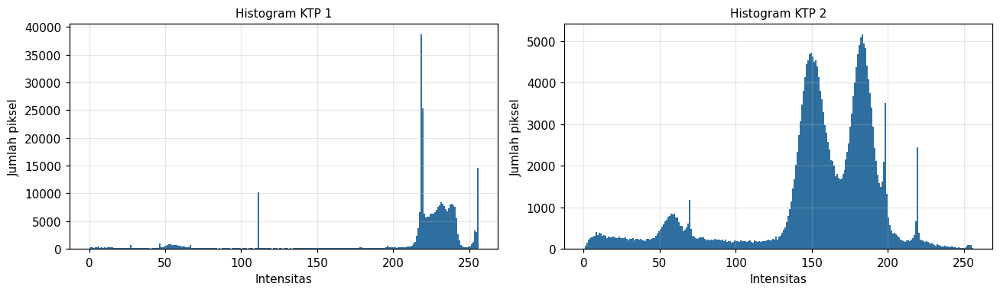

KTP 1: mean= 207.5  median=224.0  P5= 55.0  P95=254.0  std= 55.5
KTP 2: mean= 152.3  median=160.0  P5= 48.0  P95=199.0  std= 46.0


In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(12, 3.6))
for ax, citra, judul in zip(axes, [ktp1_gray, ktp2_gray], ["KTP 1", "KTP 2"]):
    histogram(citra, judul, ax=ax)
plt.tight_layout()
plt.show()

for nama, citra in [("KTP 1", ktp1_gray), ("KTP 2", ktp2_gray)]:
    p5, p50, p95 = np.percentile(citra, [5, 50, 95])
    print(f"{nama}: mean={citra.mean():6.1f}  median={p50:5.1f}  P5={p5:5.1f}  P95={p95:5.1f}  std={citra.std():5.1f}")

**Pengamatan.** Kedua histogram punya satu puncak besar di area terang (kertas/permukaan kartu) dan ekor panjang ke arah gelap (teks, foto, bayangan). Ekor gelap inilah yang ingin dipisahkan.

Pada KTP 2 puncaknya lebih lebar dan ekornya lebih "gemuk" karena latar kartu bertekstur dan ada *watermark*; ini pertanda bahwa satu ambang global akan lebih sulit bekerja rapi dibanding KTP 1.

## A.2 Global threshold: pengaruh nilai T

Satu nilai `T` untuk seluruh citra: `g(x, y) = 255` jika `f(x, y) > T`, selain itu `0`.

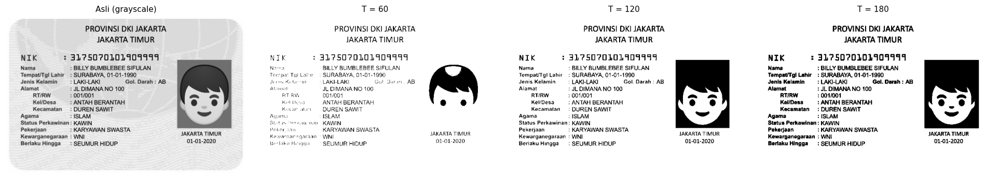

T= 60 -> piksel putih  94.0%  |  piksel hitam   6.0%
T=120 -> piksel putih  88.2%  |  piksel hitam  11.8%
T=180 -> piksel putih  85.6%  |  piksel hitam  14.4%


In [ ]:
daftar_T = [60, 120, 180]
hasil_global = [cv2.threshold(ktp1_gray, t, 255, cv2.THRESH_BINARY)[1] for t in daftar_T]

tampilkan(
    [ktp1_gray] + hasil_global,
    ["Asli (grayscale)"] + [f"T = {t}" for t in daftar_T],
    ncols=4,
    skala=4.4,
)

for t, hasil in zip(daftar_T, hasil_global):
    print(f"T={t:3d} -> piksel putih {hasil.mean() / 255 * 100:5.1f}%  |  piksel hitam {100 - hasil.mean() / 255 * 100:5.1f}%")

**Pengamatan.** Semakin besar `T`, semakin banyak piksel yang jatuh ke kelas hitam.

- `T = 60` hanya menangkap bagian yang sangat gelap, teks tipis banyak yang hilang.
- `T = 120` mulai menangkap teks, tetapi sebagian area abu-abu (bayangan, tepi kartu) ikut menjadi objek.
- `T = 180` membuat hampir seluruh permukaan kartu menjadi hitam; terjadi **over-segmentation**.

Karena tidak ada satu `T` yang pas untuk seluruh isi kartu, langkah berikutnya adalah memilih `T` otomatis (Otsu) atau `T` lokal (adaptive).

## A.3 Seluruh tipe `cv2.threshold`

`cv2.threshold(src, thresh, maxval, type)` punya lima tipe dasar. Perhatikan perbedaan cara memperlakukan piksel di atas dan di bawah ambang.

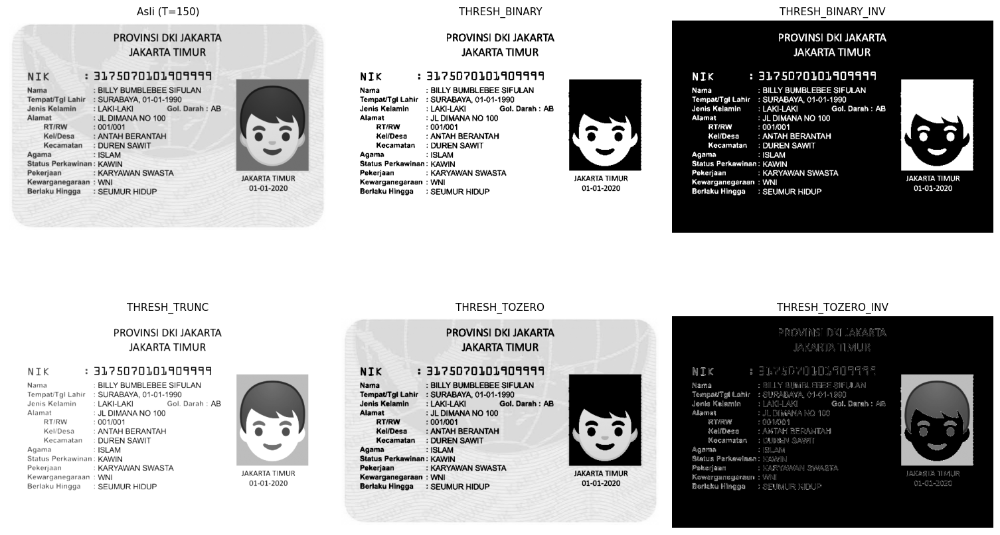

In [ ]:
T = 150
tipe_threshold = {
    "THRESH_BINARY": cv2.THRESH_BINARY,
    "THRESH_BINARY_INV": cv2.THRESH_BINARY_INV,
    "THRESH_TRUNC": cv2.THRESH_TRUNC,
    "THRESH_TOZERO": cv2.THRESH_TOZERO,
    "THRESH_TOZERO_INV": cv2.THRESH_TOZERO_INV,
}

hasil_tipe = {nama: cv2.threshold(ktp1_gray, T, 255, tipe)[1] for nama, tipe in tipe_threshold.items()}

tampilkan(
    [ktp1_gray] + list(hasil_tipe.values()),
    [f"Asli (T={T})"] + list(hasil_tipe.keys()),
    ncols=3,
    skala=4.6,
)

| Tipe | Piksel > T | Piksel ≤ T | Kegunaan khas |
|---|---|---|---|
| `THRESH_BINARY` | `maxval` (255) | 0 | objek terang di latar gelap |
| `THRESH_BINARY_INV` | 0 | `maxval` (255) | objek gelap di latar terang (teks KTP) |
| `THRESH_TRUNC` | `T` | tetap | memotong nilai tinggi (mengurangi *highlight*) |
| `THRESH_TOZERO` | tetap | 0 | mempertahankan area terang saja |
| `THRESH_TOZERO_INV` | 0 | tetap | mempertahankan area gelap saja |

Untuk kasus teks KTP (tinta gelap di kertas terang) tipe yang tepat adalah **`THRESH_BINARY_INV`**, karena teks harus menjadi piksel putih (nilai 255) pada mask.

## A.4 Otsu: ambang otomatis yang dihitung manual

Otsu mencari `T` yang memaksimalkan variansi antar kelas:

$$\sigma_B^2(t) = \frac{[\mu_T \cdot \omega(t) - \mu(t)]^2}{\omega(t)\,[1 - \omega(t)]}$$

dengan `ω(t)` = probabilitas kumulatif kelas background dan `μ(t)` = momen pertama kumulatif. Implementasi di bawah **tidak** memakai `cv2.THRESH_OTSU`; hasilnya dibandingkan dengan OpenCV sebagai validasi.

KTP 1: T manual=150  T OpenCV=150  selisih=0.0
KTP 2: T manual=111  T OpenCV=111  selisih=0.0


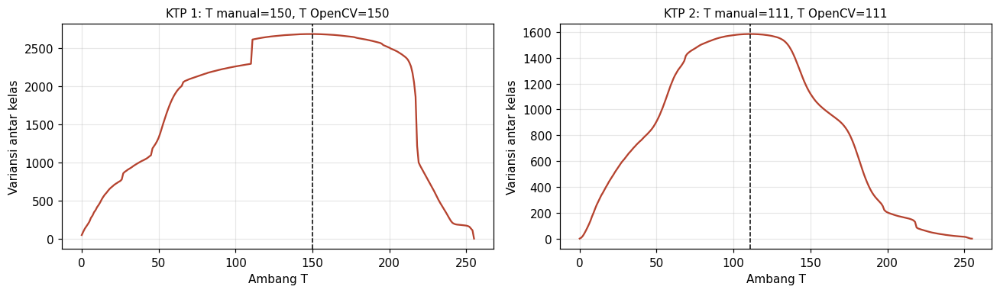

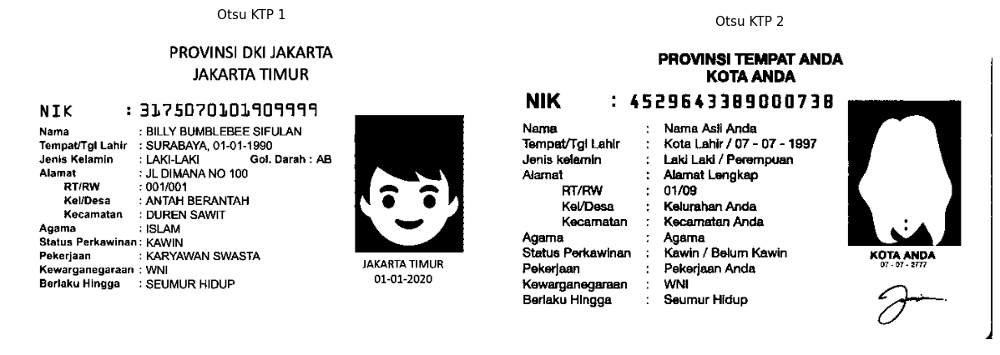

In [ ]:
def otsu_manual(citra):
    """Hitung ambang Otsu dari histogram; mengembalikan (T, kurva variansi antar kelas)."""
    hist = np.bincount(citra.ravel(), minlength=256).astype(np.float64)
    p = hist / hist.sum()
    omega = np.cumsum(p)
    mu = np.cumsum(p * np.arange(256))
    mu_total = mu[-1]
    sigma_b = (mu_total * omega - mu) ** 2 / (omega * (1 - omega) + 1e-12)
    return int(np.argmax(sigma_b)), sigma_b


fig, axes = plt.subplots(1, 2, figsize=(12, 3.6))
for ax, citra, judul in zip(axes, [ktp1_gray, ktp2_gray], ["KTP 1", "KTP 2"]):
    t_manual, kurva = otsu_manual(citra)
    t_cv2, _ = cv2.threshold(citra, 0, 255, cv2.THRESH_BINARY + cv2.THRESH_OTSU)
    ax.plot(kurva[:256], color="#b5432f")
    ax.axvline(t_manual, color="black", ls="--", lw=1)
    ax.set_title(f"{judul}: T manual={t_manual}, T OpenCV={int(t_cv2)}", fontsize=10)
    ax.set_xlabel("Ambang T")
    ax.set_ylabel("Variansi antar kelas")
    ax.grid(alpha=0.3)
    print(f"{judul}: T manual={t_manual}  T OpenCV={int(t_cv2)}  selisih={abs(t_manual - t_cv2)}")
plt.tight_layout()
plt.show()

_, otsu_ktp1 = cv2.threshold(ktp1_gray, 0, 255, cv2.THRESH_BINARY + cv2.THRESH_OTSU)
_, otsu_ktp2 = cv2.threshold(ktp2_gray, 0, 255, cv2.THRESH_BINARY + cv2.THRESH_OTSU)
tampilkan([otsu_ktp1, otsu_ktp2], ["Otsu KTP 1", "Otsu KTP 2"], ncols=2, skala=5.5)

**Pengamatan.** Hasil manual dan OpenCV identik, jadi implementasi histogram sudah benar. Kurva variansi antar kelas punya satu puncak yang jelas, artinya histogram memang kira-kira bimodal.

Ambang Otsu KTP 1 jauh lebih tinggi daripada KTP 2 karena permukaan kartunya lebih terang. Ini menunjukkan kelebihan Otsu: nilainya menyesuaikan citra, tidak perlu ditebak.

## A.5 Validasi dengan contoh perhitungan slide (citra 6×6)

Slide memberikan citra 6×6 dengan jumlah piksel per intensitas `8 7 2 6 9 4` dan tabel *within-class variance*. Kita reproduksi perhitungan itu untuk memastikan rumus yang dipakai benar.

In [ ]:
contoh = np.repeat(np.arange(6), [8, 7, 2, 6, 9, 4]).astype(np.uint8).reshape(6, 6)
print("Citra contoh (6x6):")
print(contoh)

nilai = contoh.ravel().astype(np.float64)
baris_tabel = []
for T in range(1, 6):
    w_b = (nilai < T).mean()
    w_f = 1 - w_b
    var_b = nilai[nilai < T].var()
    var_f = nilai[nilai >= T].var()
    baris_tabel.append([f"T = {T}", w_b, w_b * var_b + w_f * var_f])

tampilkan_tabel(baris_tabel, ["Ambang", "W_b", "Within-class variance"], desimal=4)

t_manual, _ = otsu_manual(contoh)
t_cv2, _ = cv2.threshold(contoh, 0, 255, cv2.THRESH_BINARY + cv2.THRESH_OTSU)
print(f"\nOtsu manual (gaya OpenCV, background <= T) = {t_manual}")
print(f"Otsu OpenCV                                = {int(t_cv2)}")
print(f"Konvensi slide (foreground >= T)           = {t_manual + 1}")

Citra contoh (6x6):
[[0 0 0 0 0 0]
 [0 0 1 1 1 1]
 [1 1 1 2 2 3]
 [3 3 3 3 3 4]
 [4 4 4 4 4 4]
 [4 4 5 5 5 5]]
---------------------------------------------------
Ambang  W_b                 Within-class variance  
---------------------------------------------------
T = 1   0.2222              1.5268                 
T = 2   0.4167              0.5561                 
T = 3   0.4722              0.4909                 
T = 4   0.6389              0.9779                 
T = 5   0.8889              2.2491                 
---------------------------------------------------

Otsu manual (gaya OpenCV, background <= T) = 2
Otsu OpenCV                                = 2
Konvensi slide (foreground >= T)           = 3


**Pengamatan.** Nilai *within-class variance* yang dihitung persis sama dengan tabel slide: `1.5268`, `0.5561`, `0.4909`, `0.9779`, `2.2491`, dengan minimum di `T = 3` (konvensi slide: `foreground ≥ T`).

OpenCV mengembalikan `2`, bukan `3`, karena `cv2.threshold` memakai aturan `piksel > T`. Nilai `T = 2` pada OpenCV sama artinya dengan `T = 3` pada slide — keduanya memisahkan `{0, 1, 2}` dari `{3, 4, 5}`. Ini penting agar tidak bingung saat membandingkan hasil hitung manual dengan OpenCV.

## A.6 Adaptive threshold: ambang lokal

`T(x, y) = rata-rata tetangga (blockSize × blockSize) − C`. Cocok ketika pencahayaan tidak merata, karena setiap piksel punya ambangnya sendiri.

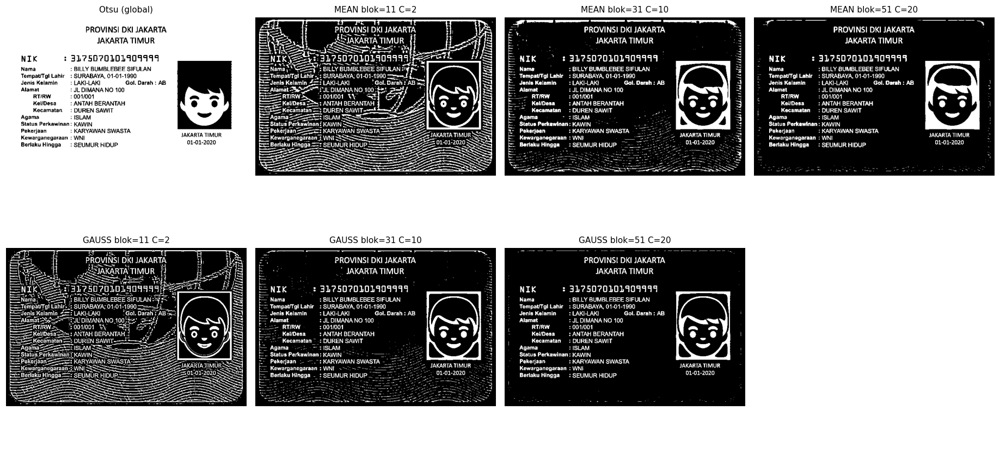

In [ ]:
kasus_adaptive = {
    "MEAN blok=11 C=2": (cv2.ADAPTIVE_THRESH_MEAN_C, 11, 2),
    "MEAN blok=31 C=10": (cv2.ADAPTIVE_THRESH_MEAN_C, 31, 10),
    "MEAN blok=51 C=20": (cv2.ADAPTIVE_THRESH_MEAN_C, 51, 20),
    "GAUSS blok=11 C=2": (cv2.ADAPTIVE_THRESH_GAUSSIAN_C, 11, 2),
    "GAUSS blok=31 C=10": (cv2.ADAPTIVE_THRESH_GAUSSIAN_C, 31, 10),
    "GAUSS blok=51 C=20": (cv2.ADAPTIVE_THRESH_GAUSSIAN_C, 51, 20),
}

hasil_adaptive = {
    nama: cv2.adaptiveThreshold(ktp1_gray, 255, metode, cv2.THRESH_BINARY_INV, blok, c)
    for nama, (metode, blok, c) in kasus_adaptive.items()
}

tampilkan(
    [otsu_ktp1] + list(hasil_adaptive.values()),
    ["Otsu (global)"] + list(hasil_adaptive.keys()),
    ncols=4,
    skala=4.2,
)

**Pengamatan.**

- `blockSize` kecil (11) membuat ambang sangat lokal, sehingga **noise dan tekstur** ikut menjadi objek (banyak bintik putih).
- `blockSize` besar (51) membuat ambang lebih halus, tetapi garis teks menjadi lebih tebal karena ambang ikut terpengaruh area yang lebih luas.
- `C` yang besar membuat ambang lebih rendah (lebih sedikit piksel dianggap objek); `C` kecil membuat mask "gemuk".
- `MEAN` lebih cepat, `GAUSSIAN` lebih halus karena piksel dekat pusat blok diberi bobot lebih besar.

Adaptive threshold sangat membantu pada citra dengan bayangan gradien, tetapi pada KTP yang pencahayaannya cukup rata hasil Otsu sudah lebih bersih.

## A.7 Evaluasi kuantitatif: kapan adaptive benar-benar menang?

Agar penilaian tidak hanya berdasarkan "kelihatan bagus", kita buat **papan teks sintetis** yang punya *ground truth* pasti, lalu tambahkan **gradien pencahayaan** (bayangan dari kiri ke kanan) dan noise. Setiap metode diukur dengan IoU dan Dice.

------------------------------------------------------------------------------------------------------
Metode             IoU                  Dice                 Presisi              Recall              
------------------------------------------------------------------------------------------------------
Global T=100       0.353                0.522                0.368                0.899               
Global T=127       0.248                0.397                0.250                0.955               
Otsu               0.220                0.361                0.222                0.969               
Adaptive MEAN 31   0.782                0.877                0.939                0.823               
Adaptive GAUSS 31  0.753                0.859                0.932                0.797               
Adaptive GAUSS 51  0.803                0.891                0.999                0.804               
-------------------------------------------------------------------------

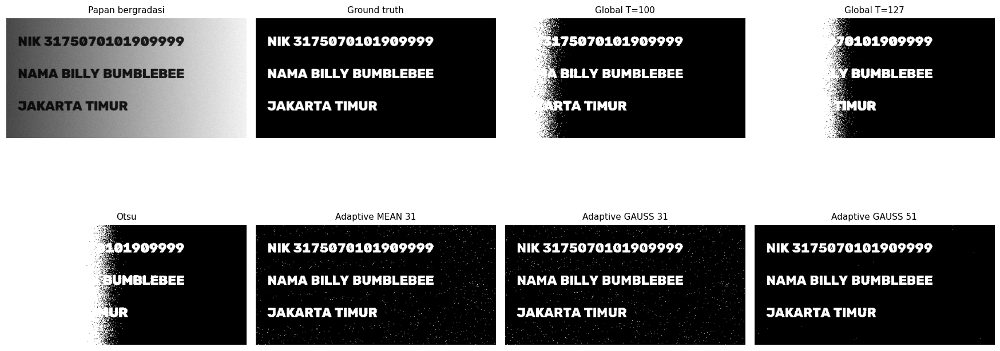

In [ ]:
def papan_teks_bergradasi(tinggi=260, lebar=520, gradasi=(0.30, 1.0), noise=4.0):
    """Papan teks sintetis + ground truth + bayangan gradien."""
    papan = np.full((tinggi, lebar), 235, np.uint8)
    gt = np.zeros((tinggi, lebar), np.uint8)
    baris = ["NIK 3175070101909999", "NAMA BILLY BUMBLEBEE", "JAKARTA TIMUR"]
    for i, teks in enumerate(baris):
        y = 60 + i * 70
        cv2.putText(papan, teks, (25, y), cv2.FONT_HERSHEY_DUPLEX, 1.0, 35, 2, cv2.LINE_AA)
        cv2.putText(gt, teks, (25, y), cv2.FONT_HERSHEY_DUPLEX, 1.0, 255, 2, cv2.LINE_AA)

    gelap, terang = gradasi
    gradien = np.linspace(gelap, terang, lebar, dtype=np.float32)
    papan = papan.astype(np.float32) * gradien[None, :]

    rng = np.random.default_rng(42)
    papan = papan + rng.normal(0, noise, papan.shape)
    return np.clip(papan, 0, 255).astype(np.uint8), gt


papan, gt_papan = papan_teks_bergradasi()

metode_papan = {
    "Global T=100": cv2.threshold(papan, 100, 255, cv2.THRESH_BINARY_INV)[1],
    "Global T=127": cv2.threshold(papan, 127, 255, cv2.THRESH_BINARY_INV)[1],
    "Otsu": cv2.threshold(papan, 0, 255, cv2.THRESH_BINARY_INV + cv2.THRESH_OTSU)[1],
    "Adaptive MEAN 31": cv2.adaptiveThreshold(papan, 255, cv2.ADAPTIVE_THRESH_MEAN_C, cv2.THRESH_BINARY_INV, 31, 10),
    "Adaptive GAUSS 31": cv2.adaptiveThreshold(papan, 255, cv2.ADAPTIVE_THRESH_GAUSSIAN_C, cv2.THRESH_BINARY_INV, 31, 10),
    "Adaptive GAUSS 51": cv2.adaptiveThreshold(papan, 255, cv2.ADAPTIVE_THRESH_GAUSSIAN_C, cv2.THRESH_BINARY_INV, 51, 15),
}

baris_eval = []
for nama, mask in metode_papan.items():
    m = metrik_biner(mask, gt_papan)
    baris_eval.append([nama, m["IoU"], m["Dice"], m["Presisi"], m["Recall"]])

tampilkan_tabel(baris_eval, ["Metode", "IoU", "Dice", "Presisi", "Recall"])

tampilkan(
    [papan, gt_papan] + list(metode_papan.values()),
    ["Papan bergradasi"] + ["Ground truth"] + list(metode_papan.keys()),
    ncols=4,
    skala=4.0,
)

**Pengamatan.**

- Pada citra dengan bayangan gradien, ambang **global** (termasuk Otsu) hanya bisa memisahkan teks di satu sisi citra; sisi yang lebih gelap ikut menjadi objek atau teksnya hilang. IoU-nya paling rendah.
- **Adaptive** mempertahankan teks di kedua sisi karena ambangnya mengikuti kecerahan lokal. `blockSize` yang sesuai (31–51) memberi IoU tertinggi.
- Papan ini juga memperlihatkan kelemahan adaptive: di area polos yang gelap, noise kecil bisa melewati ambang lokal sehingga muncul bintik. Karena itu adaptive biasanya diikuti operasi morfologi (opening) untuk membersihkan komponen kecil.

Kesimpulan praktis: **pencahayaan merata → Otsu/global; pencahayaan tidak merata → adaptive**.

## A.8 Region growing (berbasis wilayah)

Region growing mulai dari satu *seed*, lalu menambahkan tetangga yang selisih intensitasnya terhadap rata-rata region masih di bawah `T`. Berbeda dengan thresholding, metode ini memperhatikan **keterhubungan** piksel.

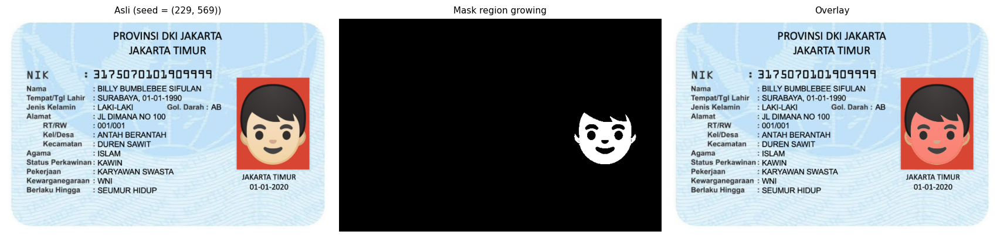

Luas region: 8225 piksel (2.6% citra)


In [ ]:
def region_growing(citra, seed, ambang, koneksi=4):
    """Segmentasi region growing manual (BFS). seed = (baris, kolom)."""
    tinggi, lebar = citra.shape
    mask = np.zeros((tinggi, lebar), np.uint8)
    tetangga = [(1, 0), (-1, 0), (0, 1), (0, -1)]
    if koneksi == 8:
        tetangga += [(1, 1), (1, -1), (-1, 1), (-1, -1)]

    antrean = deque([seed])
    mask[seed] = 1
    rata = float(citra[seed])
    jumlah = 1

    while antrean:
        y, x = antrean.popleft()
        for dy, dx in tetangga:
            ny, nx = y + dy, x + dx
            if 0 <= ny < tinggi and 0 <= nx < lebar and mask[ny, nx] == 0:
                if abs(float(citra[ny, nx]) - rata) <= ambang:
                    mask[ny, nx] = 1
                    antrean.append((ny, nx))
                    rata = (rata * jumlah + float(citra[ny, nx])) / (jumlah + 1)
                    jumlah += 1
    return mask


tinggi1, lebar1 = ktp1_gray.shape
seed_wajah = (tinggi1 // 2, int(lebar1 * 0.82))
mask_wajah = region_growing(ktp1_gray, seed_wajah, ambang=25)

overlay = ktp1_rgb.copy()
overlay[mask_wajah == 1] = (overlay[mask_wajah == 1] * 0.35 + np.array([255, 90, 90]) * 0.65).astype(np.uint8)

tampilkan(
    [ktp1_rgb, mask_wajah, overlay],
    [f"Asli (seed = {seed_wajah})", "Mask region growing", "Overlay"],
    ncols=3,
    skala=5.2,
)
print(f"Luas region: {mask_wajah.sum()} piksel ({mask_wajah.mean() * 100:.1f}% citra)")

**Pengamatan.** Region growing berhasil memisahkan **wajah** dari latar merah dan rambut, karena warna kulit relatif homogen dan terhubung. Region berhenti sendiri saat bertemu rambut yang jauh lebih gelap.

Sifat penting metode ini: hasilnya **selalu satu region terhubung**. Kalau seed diletakkan di area lain, region yang tumbuh juga berbeda — inilah kelemahan utamanya (sangat sensitif terhadap seed dan ambang).

## A.9 Splitting & merging (quadtree)

Kebalikan region growing: citra dianggap satu region besar. Region yang tidak homogen (simpangan baku > ambang) dibagi menjadi 4 kuadran secara rekursif, lalu blok tetangga yang rata-ratanya mirip digabung kembali.

Blok daun hasil splitting: 787
Region setelah merging  : 249


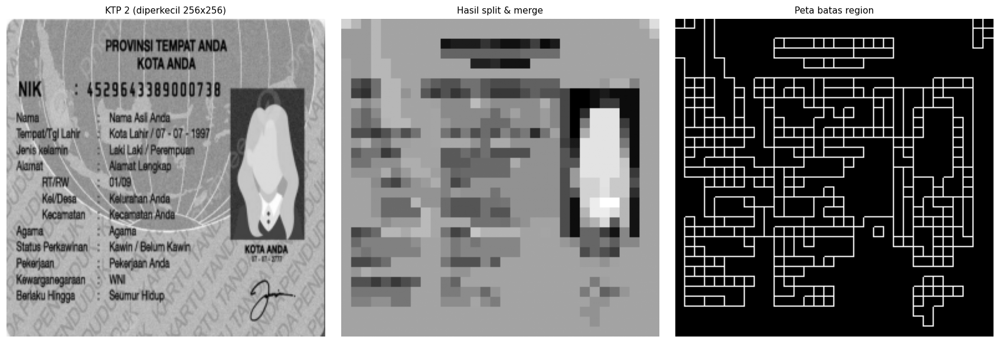

In [ ]:
def split_and_merge(citra, ambang_std=14.0, ukuran_min=8, ambang_gabung=8.0):
    """Quadtree splitting + merging berbasis rata-rata blok."""
    tinggi, lebar = citra.shape
    n = 1
    while n < max(tinggi, lebar):
        n *= 2
    papan = np.full((n, n), int(citra.mean()), np.uint8)
    papan[:tinggi, :lebar] = citra

    daun = []

    def bagi(x, y, s):
        blok = papan[y:y + s, x:x + s]
        if s <= ukuran_min or blok.std() <= ambang_std:
            daun.append((x, y, s, float(blok.mean())))
            return
        setengah = s // 2
        for dy in (0, setengah):
            for dx in (0, setengah):
                bagi(x + dx, y + dy, setengah)

    bagi(0, 0, n)

    induk = list(range(len(daun)))

    def cari(i):
        while induk[i] != i:
            induk[i] = induk[induk[i]]
            i = induk[i]
        return i

    def gabung(i, j):
        ri, rj = cari(i), cari(j)
        if ri != rj:
            induk[rj] = ri

    def bersebelahan(a, b):
        x1, y1, s1, _ = a
        x2, y2, s2, _ = b
        tumpang_x = min(x1 + s1, x2 + s2) - max(x1, x2)
        tumpang_y = min(y1 + s1, y2 + s2) - max(y1, y2)
        if tumpang_x > 0 and (y1 + s1 == y2 or y2 + s2 == y1):
            return True
        if tumpang_y > 0 and (x1 + s1 == x2 or x2 + s2 == x1):
            return True
        return False

    for i in range(len(daun)):
        for j in range(i + 1, len(daun)):
            if abs(daun[i][3] - daun[j][3]) <= ambang_gabung and bersebelahan(daun[i], daun[j]):
                gabung(i, j)

    label = np.zeros((n, n), np.int32)
    for i, (x, y, s, _) in enumerate(daun):
        label[y:y + s, x:x + s] = cari(i)

    total = {}
    jumlah = {}
    for i, (x, y, s, m) in enumerate(daun):
        akar = cari(i)
        total[akar] = total.get(akar, 0.0) + m * s * s
        jumlah[akar] = jumlah.get(akar, 0) + s * s

    kanvas = np.zeros((n, n), np.uint8)
    for akar in total:
        kanvas[label == akar] = int(round(total[akar] / jumlah[akar]))

    batas = np.zeros((n, n), np.uint8)
    batas[:, :-1] |= ((label[:, :-1] != label[:, 1:]) * 255).astype(np.uint8)
    batas[:-1, :] |= ((label[:-1, :] != label[1:, :]) * 255).astype(np.uint8)

    return kanvas[:tinggi, :lebar], batas[:tinggi, :lebar], label[:tinggi, :lebar], len(daun)


kecil = cv2.resize(ktp2_gray, (256, 256), interpolation=cv2.INTER_AREA)
kanvas, batas, label_sm, jumlah_daun = split_and_merge(kecil)

print(f"Blok daun hasil splitting: {jumlah_daun}")
print(f"Region setelah merging  : {len(np.unique(label_sm))}")

tampilkan(
    [kecil, kanvas, batas],
    ["KTP 2 (diperkecil 256x256)", "Hasil split & merge", "Peta batas region"],
    ncols=3,
    skala=5.2,
)

**Pengamatan.** Splitting memecah citra menjadi blok-blok persegi: area bertekstur (latar kartu, *watermark*) menjadi blok kecil, sedangkan area rata (bagian dalam foto) tetap sebagai blok besar. Merging menyatukan blok tetangga yang rata-ratanya mirip sehingga batas region mengikuti perubahan intensitas.

Ciri khas hasilnya adalah **batas berbentuk kotak-kotak** (artefak quadtree), karena keputusan hanya dibuat pada grid pangkat dua. Metode ini tidak butuh seed, tetapi kurang halus untuk objek dengan bentuk lengkung.

## A.10 Watershed

Watershed memandang intensitas sebagai ketinggian topografi. Tanpa *marker*, noise menciptakan ribuan cekungan kecil → **over-segmentation**. Solusinya *marker-controlled watershed*: marker dibuat dari puncak *distance transform*, lalu air dituang dari marker tersebut.

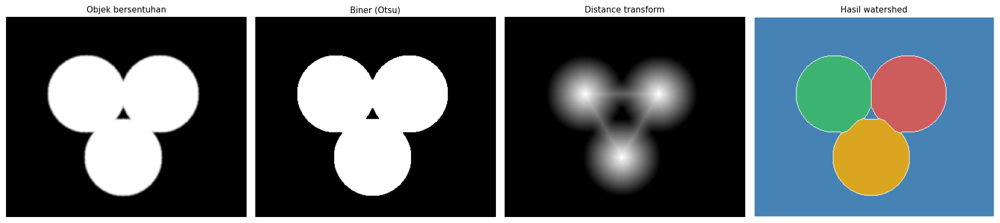

Jumlah objek terdeteksi: 3 (sebenarnya 3)


In [ ]:
def watershed_marker(biner):
    """Marker-controlled watershed pada mask biner; mengembalikan label dan gambar batas."""
    biner = (biner > 0).astype(np.uint8)
    jarak = cv2.distanceTransform(biner, cv2.DIST_L2, 5)
    inti = (jarak > 0.45 * jarak.max()).astype(np.uint8)
    jumlah, penanda = cv2.connectedComponents(inti)

    marker = penanda + 1
    marker[inti == 0] = 0
    marker[biner == 0] = 1

    hasil = cv2.watershed(cv2.cvtColor((biner * 255).astype(np.uint8), cv2.COLOR_GRAY2BGR), marker.copy())
    return hasil, jarak, jumlah - 1


koin = np.full((300, 360), 45, np.uint8)
for (x, y, r) in [(120, 115, 58), (230, 115, 58), (175, 210, 58)]:
    cv2.circle(koin, (x, y), r, 205, -1)
koin = cv2.GaussianBlur(koin, (5, 5), 1.2)

_, biner_koin = cv2.threshold(koin, 0, 255, cv2.THRESH_BINARY + cv2.THRESH_OTSU)
biner_koin = cv2.morphologyEx(biner_koin, cv2.MORPH_OPEN, np.ones((3, 3), np.uint8))
label_koin, jarak_koin, jumlah_koin = watershed_marker(biner_koin)

berwarna = np.zeros((*label_koin.shape, 3), np.uint8)
warna = np.array([[0, 0, 0], [70, 130, 180], [60, 179, 113], [205, 92, 92], [218, 165, 32], [147, 112, 219]], np.uint8)
for nilai in np.unique(label_koin):
    if nilai > 0:
        berwarna[label_koin == nilai] = warna[nilai % len(warna)]
berwarna[label_koin == -1] = (255, 255, 255)

tampilkan(
    [koin, biner_koin, jarak_koin / max(jarak_koin.max(), 1), berwarna],
    ["Objek bersentuhan", "Biner (Otsu)", "Distance transform", "Hasil watershed"],
    ncols=4,
    skala=4.2,
)
print(f"Jumlah objek terdeteksi: {jumlah_koin} (sebenarnya 3)")

**Pengamatan.** Tiga lingkaran yang saling bersentuhan berhasil dipisahkan menjadi **3 region** karena setiap lingkaran punya puncak *distance transform* sendiri. Piksel batas ditandai `-1` (putih pada gambar) — inilah "bendungan" yang dibangun saat air dari dua cekungan bertemu.

Tanpa marker, watershed pada citra yang sama menghasilkan ratusan region kecil akibat tekstur dan noise.

## A.11 K-Means clustering warna

Jika thresholding 1 kanal tidak cukup, piksel dapat dikelompokkan berdasarkan **vektor warna** `[R, G, B]`. K-Means meminimalkan total jarak kuadrat piksel ke centroid cluster-nya.

----------------------------------------------
Cluster    R    G    B    % piksel            
----------------------------------------------
Cluster 0  66   47   57   14.1                
Cluster 1  132  177  204  82.1                
Cluster 2  247  202  23   3.8                 
----------------------------------------------


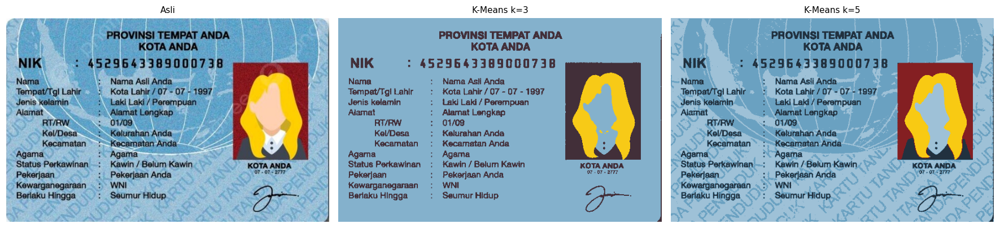

In [ ]:
def segmentasi_kmeans(citra_rgb, k, acak=42):
    """Segmentasi warna dengan K-Means; mengembalikan citra hasil, label 2D, dan centroid."""
    fitur = citra_rgb.reshape(-1, 3).astype(np.float32)
    model = KMeans(n_clusters=k, n_init=5, random_state=acak).fit(fitur)
    pusat = np.uint8(model.cluster_centers_)
    label = model.labels_.reshape(citra_rgb.shape[:2])
    return pusat[label], label, pusat


seg3, label3, pusat3 = segmentasi_kmeans(ktp2_rgb, 3)
seg5, label5, pusat5 = segmentasi_kmeans(ktp2_rgb, 5)

bagian = [(label3 == i).mean() * 100 for i in range(3)]
baris_klaster = [[f"Cluster {i}", int(pusat3[i][0]), int(pusat3[i][1]), int(pusat3[i][2]), bagian[i]] for i in range(3)]
tampilkan_tabel(baris_klaster, ["Cluster", "R", "G", "B", "% piksel"], desimal=1)

tampilkan([ktp2_rgb, seg3, seg5], ["Asli", "K-Means k=3", "K-Means k=5"], ncols=3, skala=5.4)

**Pengamatan.** K-Means mengubah citra menjadi beberapa warna rata. Dengan `k = 3`, kartu, foto, dan latar/aksen terpisah menjadi tiga kelompok besar; detail kecil (tekstur kertas, *watermark*) hilang.

Kenaikan `k` membuat hasil lebih mirip asli tetapi segmentasinya makin tidak bermakna: satu objek bisa terpecah menjadi beberapa cluster hanya karena gradasi warna. Jumlah cluster harus dipilih sesuai tujuan.

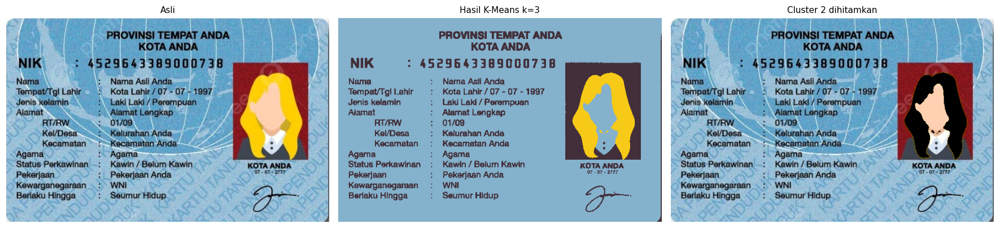

Cluster yang dihitamkan: 2 (porsi 3.8%)


In [ ]:
klaster_dihitamkan = int(np.argmin(bagian))
salinan = ktp2_rgb.copy()
salinan[label3 == klaster_dihitamkan] = 0

tampilkan(
    [ktp2_rgb, seg3, salinan],
    ["Asli", "Hasil K-Means k=3", f"Cluster {klaster_dihitamkan} dihitamkan"],
    ncols=3,
    skala=5.4,
)
print(f"Cluster yang dihitamkan: {klaster_dihitamkan} (porsi {bagian[klaster_dihitamkan]:.1f}%)")

Menghitamkan satu cluster adalah cara cepat membuat *mask* objek: semua piksel dengan label tersebut dihapus. Ini berguna sebagai langkah awal pemisahan objek dari latar.

## A.12 Segmentasi rentang warna (HSV)

Kanal HSV memisahkan **warna (Hue)** dari **kecerahan (Value)**, sehingga rentang warna lebih stabil terhadap perubahan pencahayaan dibanding RGB. Rentang merah harus dicek di dua sisi lingkaran Hue (0–12 dan 168–180).

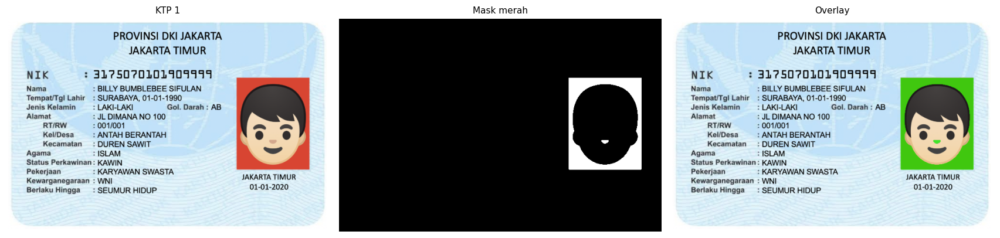

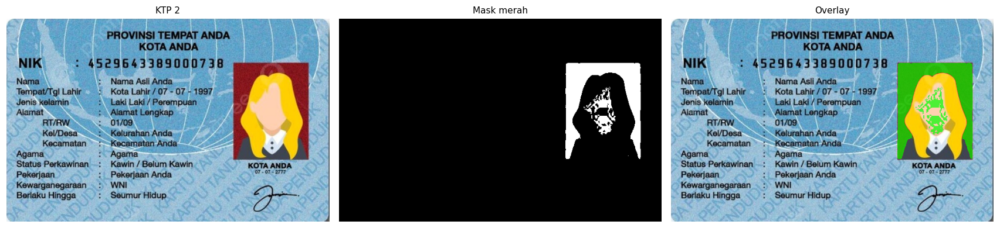

KTP 1: piksel merah  3.63%
KTP 2: piksel merah  4.87%


In [ ]:
def mask_rentang_merah(citra_rgb, s_min=70, v_min=60):
    """Mask area merah pada citra RGB memakai dua rentang Hue."""
    hsv = cv2.cvtColor(citra_rgb, cv2.COLOR_RGB2HSV)
    rendah = cv2.inRange(hsv, np.array([0, s_min, v_min]), np.array([12, 255, 255]))
    tinggi = cv2.inRange(hsv, np.array([168, s_min, v_min]), np.array([180, 255, 255]))
    return cv2.bitwise_or(rendah, tinggi)


mask1 = mask_rentang_merah(ktp1_rgb)
mask2 = mask_rentang_merah(ktp2_rgb)

overlay1 = ktp1_rgb.copy()
overlay1[mask1 > 0] = (overlay1[mask1 > 0] * 0.3 + np.array([0, 255, 0]) * 0.7).astype(np.uint8)
overlay2 = ktp2_rgb.copy()
overlay2[mask2 > 0] = (overlay2[mask2 > 0] * 0.3 + np.array([0, 255, 0]) * 0.7).astype(np.uint8)

tampilkan([ktp1_rgb, mask1, overlay1], ["KTP 1", "Mask merah", "Overlay"], ncols=3, skala=5.2)
tampilkan([ktp2_rgb, mask2, overlay2], ["KTP 2", "Mask merah", "Overlay"], ncols=3, skala=5.2)

for nama, mask in [("KTP 1", mask1), ("KTP 2", mask2)]:
    print(f"{nama}: piksel merah {mask.mean() / 255 * 100:5.2f}%")

**Pengamatan.** Pada KTP 1 latar pas foto berwarna merah pekat dan seragam, sehingga mask-nya hampir sempurna. Pada KTP 2 mask terpecah oleh rambut pirang yang menutupi sebagian latar merah, dan tekstur kartu menghasilkan beberapa bintik palsu.

Rentang warna adalah metode paling langsung untuk mengambil objek berwarna khas, tetapi hasilnya masih perlu dibersihkan dengan morfologi sebelum dipakai.

---

# B. Tugas 1 — Segmentasi Teks pada KTP 1

**Tujuan:** memilih metode threshold yang paling tepat untuk memisahkan **teks** dari permukaan kartu, lalu membuktikan pilihan tersebut pada kondisi pencahayaan yang tidak merata.

**Citra:** `ktp1_fulan.jpg` — kartu terang, teks hitam, latar relatif rata (kasus "mudah").

### 1a. Area teks dan ground truth semu

Area teks diambil dari sisi kiri kartu (kolom NIK sampai keterangan). *Ground truth* dibuat dari citra asli dengan ambang tetap yang dipilih secara manual, lalu komponen sangat kecil dibuang. Ground truth ini dipakai sebagai pembanding, bukan sebagai kebenaran mutlak.

Ukuran ROI teks: (321, 458)
Rasio tinta ground truth: 10.21%


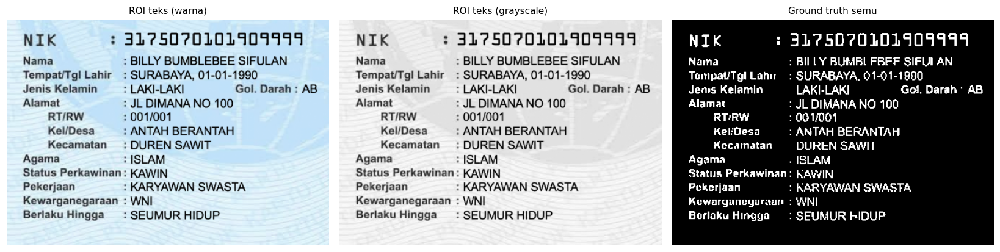

In [ ]:
tinggi1, lebar1 = ktp1_gray.shape
y0, y1 = int(tinggi1 * 0.20), int(tinggi1 * 0.90)
x0, x1 = int(lebar1 * 0.03), int(lebar1 * 0.69)

roi = ktp1_gray[y0:y1, x0:x1]
roi_rgb = ktp1_rgb[y0:y1, x0:x1]

gt_roi = cv2.threshold(roi, 150, 255, cv2.THRESH_BINARY_INV)[1]
gt_roi = cv2.morphologyEx(gt_roi, cv2.MORPH_OPEN, np.ones((2, 2), np.uint8))

print("Ukuran ROI teks:", roi.shape)
print(f"Rasio tinta ground truth: {gt_roi.mean() / 255 * 100:.2f}%")

tampilkan([roi_rgb, roi, gt_roi], ["ROI teks (warna)", "ROI teks (grayscale)", "Ground truth semu"], ncols=3, skala=5.0)

### 1b. Enam metode threshold pada area teks

Semua metode memakai `THRESH_BINARY_INV` agar tinta menjadi putih.

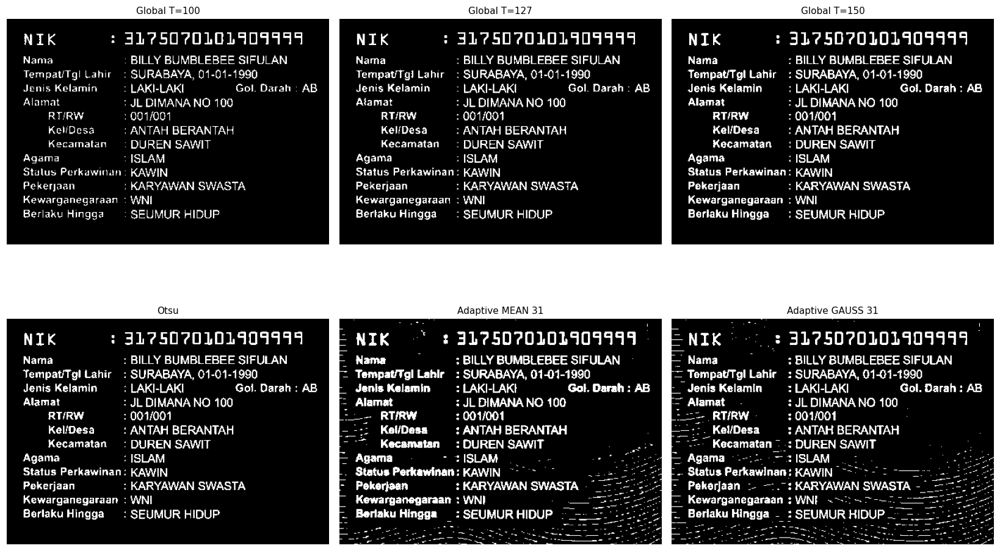

In [ ]:
metode_teks = {
    "Global T=100": cv2.threshold(roi, 100, 255, cv2.THRESH_BINARY_INV)[1],
    "Global T=127": cv2.threshold(roi, 127, 255, cv2.THRESH_BINARY_INV)[1],
    "Global T=150": cv2.threshold(roi, 150, 255, cv2.THRESH_BINARY_INV)[1],
    "Otsu": cv2.threshold(roi, 0, 255, cv2.THRESH_BINARY_INV + cv2.THRESH_OTSU)[1],
    "Adaptive MEAN 31": cv2.adaptiveThreshold(roi, 255, cv2.ADAPTIVE_THRESH_MEAN_C, cv2.THRESH_BINARY_INV, 31, 10),
    "Adaptive GAUSS 31": cv2.adaptiveThreshold(roi, 255, cv2.ADAPTIVE_THRESH_GAUSSIAN_C, cv2.THRESH_BINARY_INV, 31, 10),
}

tampilkan(list(metode_teks.values()), list(metode_teks.keys()), ncols=3, skala=5.0)

### 1c. Metrik pada area teks asli

Karena *ground truth* piksel-per-piksel tidak tersedia, penilaian pada citra asli memakai ukuran tidak langsung:

- **Rasio tinta** — harus mendekati rasio ground truth semu. Terlalu kecil berarti huruf hilang; terlalu besar berarti latar ikut masuk.
- **Jumlah komponen besar** — mendekati jumlah karakter. Nilai jauh di bawah ground truth berarti huruf saling menempel.
- **Luas median komponen** — mendeteksi garis yang menggembung (nilai terlalu besar).

IoU pada citra asli **tidak** dipakai, karena ground truth semu dibuat dari ambang `T = 150` sehingga metode dengan `T` yang sama akan menang secara tidak adil. Uji IoU yang adil dilakukan pada 1d, di mana ground truth berasal dari citra **bersih** sedangkan metode diuji pada citra **berbayang**.

In [ ]:
baris_teks = []
for nama, mask in metode_teks.items():
    st = statistik_mask(mask)
    baris_teks.append([nama, st["tinta"], st["komponen_besar"], st["luas_median"]])

tampilkan_tabel(baris_teks, ["Metode", "Tinta (%)", "Komponen besar", "Luas median"], desimal=2)

st_gt = statistik_mask(gt_roi)
print(f"\nGround truth semu: tinta {st_gt['tinta']:.2f}%  komponen besar {st_gt['komponen_besar']}  luas median {st_gt['luas_median']:.0f}")

--------------------------------------------------------------------
Metode             Tinta (%)           Komponen besar  Luas median  
--------------------------------------------------------------------
Global T=100       7.63                254             30.00        
Global T=127       9.06                261             41.00        
Global T=150       10.57               256             52.00        
Otsu               10.09               259             48.50        
Adaptive MEAN 31   14.39               216             7.00         
Adaptive GAUSS 31  13.46               268             6.00         
--------------------------------------------------------------------

Ground truth semu: tinta 10.21%  komponen besar 275  luas median 44


### 1d. Uji ketahanan: bayangan gradien pada KTP 1

Kartu KTP 1 pencahayaannya rata. Untuk menguji klaim "adaptive lebih tahan bayangan", area teks yang sama diberi **gradien pencahayaan buatan** (kiri terang → kanan gelap) dan noise. Metode diuji terhadap ground truth semu dari citra bersih.

------------------------------------------------------------------------------------------------------
Metode             IoU                  Dice                 Presisi              Recall              
------------------------------------------------------------------------------------------------------
Global T=100       0.177                0.301                0.200                0.601               
Global T=127       0.150                0.260                0.158                0.735               
Otsu               0.146                0.254                0.152                0.780               
Adaptive MEAN 31   0.424                0.596                0.527                0.685               
Adaptive GAUSS 31  0.397                0.568                0.520                0.627               
Adaptive GAUSS 51  0.425                0.597                0.561                0.637               
-------------------------------------------------------------------------

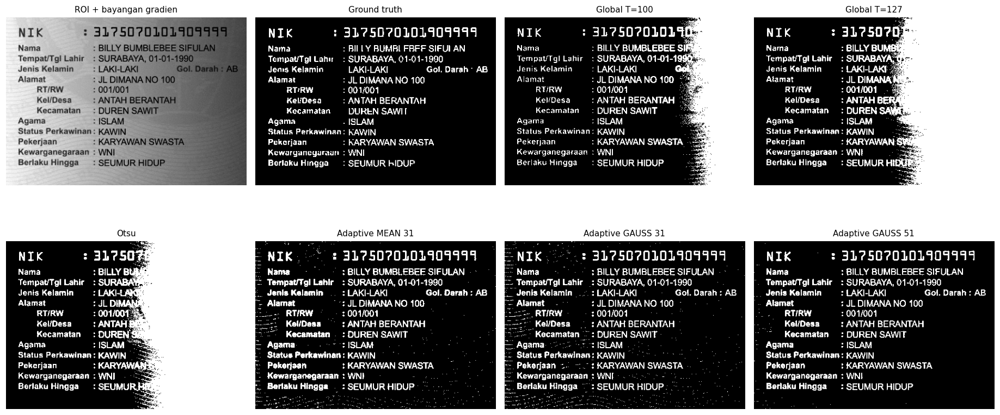

In [ ]:
lebar_roi = roi.shape[1]
bayangan = np.linspace(1.0, 0.30, lebar_roi, dtype=np.float32)[None, :]
rng = np.random.default_rng(7)
roi_bayangan = np.clip(roi.astype(np.float32) * bayangan + rng.normal(0, 3, roi.shape), 0, 255).astype(np.uint8)

metode_bayangan = {
    "Global T=100": cv2.threshold(roi_bayangan, 100, 255, cv2.THRESH_BINARY_INV)[1],
    "Global T=127": cv2.threshold(roi_bayangan, 127, 255, cv2.THRESH_BINARY_INV)[1],
    "Otsu": cv2.threshold(roi_bayangan, 0, 255, cv2.THRESH_BINARY_INV + cv2.THRESH_OTSU)[1],
    "Adaptive MEAN 31": cv2.adaptiveThreshold(roi_bayangan, 255, cv2.ADAPTIVE_THRESH_MEAN_C, cv2.THRESH_BINARY_INV, 31, 10),
    "Adaptive GAUSS 31": cv2.adaptiveThreshold(roi_bayangan, 255, cv2.ADAPTIVE_THRESH_GAUSSIAN_C, cv2.THRESH_BINARY_INV, 31, 10),
    "Adaptive GAUSS 51": cv2.adaptiveThreshold(roi_bayangan, 255, cv2.ADAPTIVE_THRESH_GAUSSIAN_C, cv2.THRESH_BINARY_INV, 51, 15),
}

baris_bayangan = []
for nama, mask in metode_bayangan.items():
    m = metrik_biner(mask, gt_roi)
    baris_bayangan.append([nama, m["IoU"], m["Dice"], m["Presisi"], m["Recall"]])

tampilkan_tabel(baris_bayangan, ["Metode", "IoU", "Dice", "Presisi", "Recall"])

tampilkan(
    [roi_bayangan, gt_roi] + list(metode_bayangan.values()),
    ["ROI + bayangan gradien", "Ground truth"] + list(metode_bayangan.keys()),
    ncols=4,
    skala=4.2,
)

**Pengamatan.** Di sini perbandingannya adil: ground truth berasal dari citra **bersih**, sedangkan semua metode diuji pada citra yang sama setelah diberi bayangan.

- Metode global runtuh: `T = 100` hanya mendapat IoU ≈ 0,18, `T = 127` ≈ 0,15, dan Otsu ≈ 0,15. Pada gambar terlihat jelas mengapa — sisi kiri yang gelap berubah menjadi blok putih besar, sedangkan teks di sisi kanan yang masih terang justru hilang. Satu nilai `T` tidak bisa benar untuk dua kecerahan yang berbeda.
- Semua varian adaptive bertahan di IoU ≈ 0,40–0,43 (Dice ≈ 0,57–0,60), sekitar **2,5× lebih baik** daripada global, karena ambangnya bergerak mengikuti kecerahan lokal.
- Adaptive belum sempurna: presisi hanya ≈ 0,52–0,56 karena noise pada area gelap ikut terangkat. Ini persis kelemahan yang disebut di teori — karena itu hasil adaptive biasanya diikuti operasi morfologi atau penyaringan komponen kecil.

### Analisis Tugas 1

1. **Pada kondisi asli (pencahayaan rata), Otsu adalah pilihan terbaik.** Otsu menemukan `T = 150` sendiri dari histogram, dan hasilnya hampir sama dengan `T = 150` manual (rasio tinta 10,09% vs 10,21%, luas median 48,5 vs 44 piksel). Artinya kita mendapat kualitas setara "nilai `T` yang tepat" **tanpa perlu menebak** nilainya. Perlu dicatat, ground truth semu memang dibuat dengan `T = 150`, sehingga metode itu otomatis paling dekat — karena itu IoU baru dipakai sebagai pembanding yang adil di bagian 1d.

2. **Global threshold sangat sensitif terhadap nilai `T`.** Selisih 27 tingkat (100 → 127) sudah mengubah mask secara nyata: pada `T` rendah tinta tertangkap hanya 7,63% (huruf tipis hilang), pada `T` tinggi naik ke 10,57% dan luas median komponen membengkak dari 30 menjadi 52 piksel (garis menebal dan huruf mulai menempel).

3. **Adaptive threshold unggul saat ada bayangan gradien.** Ambang lokal mengikuti kecerahan di sekitarnya, sehingga teks di sisi gelap tetap terdeteksi. Namun pada citra yang sudah rata, adaptive justru menangkap tekstur permukaan kartu: rasio tinta naik ke 13–14% dan luas median komponen anjlok ke 6–7 piksel (garis asli terpecah menjadi bintik-bintik kecil).

4. **Kesimpulan pemilihan metode:**
   - Kartu KTP dengan pencahayaan merata → **Otsu** (cepat, otomatis, bersih).
   - Hasil scan/foto dengan bayangan atau pencahayaan tidak merata → **adaptive Gaussian**, `blockSize` 31–51 dan `C` 10–15, lalu dibersihkan dengan opening.
   - Global `T` tetap hanya cocok jika kondisi pencahayaan dijamin seragam (misal hasil scan datar).

---

# C. Tugas 2 — Ekstraksi Pas Foto pada KTP 2

**Tujuan:** mengambil area **pas foto** dari KTP yang lebih sulit. KTP 2 punya latar kartu bertekstur, *watermark* berulang, dan rambut pirang yang menutupi sebagian latar merah foto.

**Pendekatan:** segmentasi rentang warna HSV (merah) + morfologi + kontur terbesar, lalu dibandingkan dengan K-Means sebagai metode berbasis clustering.

### 2a. Mask warna mentah dan masalahnya

Mask merah mentah dipakai lebih dulu tanpa morfologi. Perhatikan bahwa rambut memotong latar merah menjadi beberapa bagian.

Komponen mask merah (5 terbesar):
  luas= 10526  bbox=(445,88,148,189)  fill=0.376
  luas=   569  bbox=(505,192,29,32)  fill=0.613
  luas=   436  bbox=(502,159,34,18)  fill=0.712
  luas=    40  bbox=(489,178,7,6)  fill=0.952
  luas=    35  bbox=(535,195,6,6)  fill=0.972

Total 5 komponen; komponen terbesar hanya mengisi 37.6% dari bounding box-nya.

Marker watershed pada mask mentah: 3


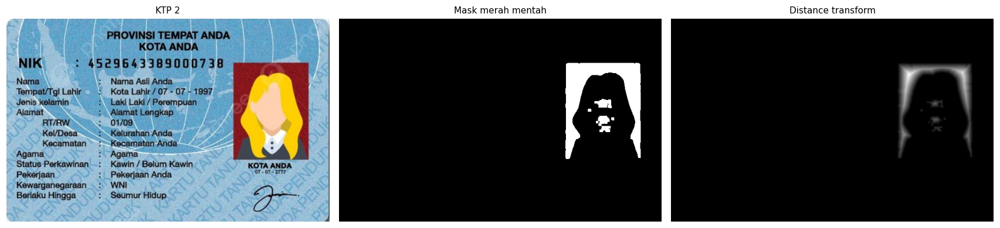

In [ ]:
mask_mentah = mask_rentang_merah(ktp2_rgb, s_min=60, v_min=50)
mask_mentah = cv2.morphologyEx(mask_mentah, cv2.MORPH_OPEN, np.ones((5, 5), np.uint8))

jumlah_komponen, label_mask, stat_mask, _ = cv2.connectedComponentsWithStats(mask_mentah, connectivity=8)
luas = stat_mask[1:, cv2.CC_STAT_AREA]
urut = np.argsort(luas)[::-1][:5]

print("Komponen mask merah (5 terbesar):")
for i in urut:
    x, y, w, h, a = stat_mask[i + 1]
    print(f"  luas={a:6d}  bbox=({x},{y},{w},{h})  fill={a / (w * h):.3f}")

luas_terbesar = luas[urut[0]]
x, y, w, h, _ = stat_mask[urut[0] + 1]
print(f"\nTotal {len(luas)} komponen; komponen terbesar hanya mengisi {luas_terbesar / (w * h) * 100:.1f}% dari bounding box-nya.")

label_ws, jarak_ws, jumlah_marker = watershed_marker(mask_mentah)
print(f"\nMarker watershed pada mask mentah: {jumlah_marker}")

tampilkan(
    [ktp2_rgb, mask_mentah, jarak_ws / max(jarak_ws.max(), 1)],
    ["KTP 2", "Mask merah mentah", "Distance transform"],
    ncols=3,
    skala=5.2,
)

**Pengamatan.** Mask merah mentah **tidak utuh**: bingkai merah terpotong-potong oleh rambut pirang dan bagian bawah foto, sehingga muncul beberapa komponen. Komponen terbesar sudah mencakup seluruh *bounding box* foto, tetapi hanya mengisi sekitar 38% luas kotak itu — artinya di dalam kotak masih ada lubang besar berisi rambut dan kemeja.

Karena itu mask tidak bisa langsung dipakai untuk mengukur luas atau membuat *crop* yang rapi: lubang-lubang tersebut harus ditutup terlebih dahulu. Watershed pada mask mentah juga menghasilkan 3 marker (bukan 1), bukti bahwa area merah benar-benar terpecah.

### 2b. Morfologi closing + kontur terbesar + crop

`closing` (dilasi lalu erosi) menutup celah sempit tanpa banyak mengubah ukuran objek. Setelah itu kontur terbesar diambil dan *bounding box*-nya dipakai untuk memotong foto.

Bounding box foto : x=445, y=88, w=148, h=189
Luas kontur       : 21397 piksel
Fill ratio        : 0.765  (1.0 = persegi penuh)
Rasio aspek w/h   : 0.783  (foto KTP umumnya 3:4 = 0.75)
Luas mask mentah  : 4.58% citra
Luas mask closing : 8.58% citra


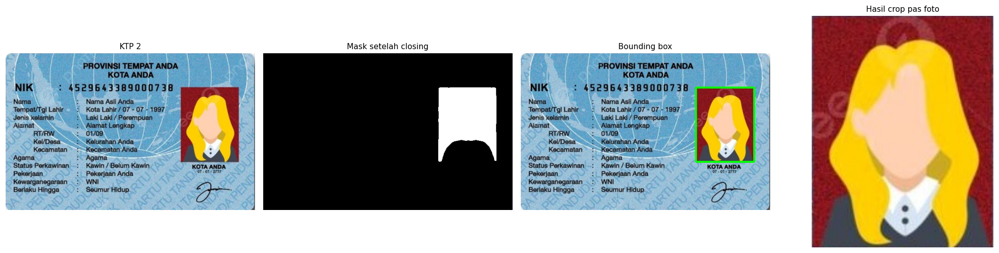

In [ ]:
kernel = cv2.getStructuringElement(cv2.MORPH_ELLIPSE, (25, 25))
mask_rapat = cv2.morphologyEx(mask_mentah, cv2.MORPH_CLOSE, kernel, iterations=3)
mask_rapat = cv2.morphologyEx(mask_rapat, cv2.MORPH_OPEN, np.ones((5, 5), np.uint8))

kontur, _ = cv2.findContours(mask_rapat, cv2.RETR_EXTERNAL, cv2.CHAIN_APPROX_SIMPLE)
kontur_terbesar = max(kontur, key=cv2.contourArea)
x, y, w, h = cv2.boundingRect(kontur_terbesar)
luas_kontur = cv2.contourArea(kontur_terbesar)
isi = luas_kontur / (w * h)

foto = ktp2_rgb[y:y + h, x:x + w]
mask_foto = mask_rapat[y:y + h, x:x + w]
merah_foto = mask_mentah[y:y + h, x:x + w]

print(f"Bounding box foto : x={x}, y={y}, w={w}, h={h}")
print(f"Luas kontur       : {luas_kontur:.0f} piksel")
print(f"Fill ratio        : {isi:.3f}  (1.0 = persegi penuh)")
print(f"Rasio aspek w/h   : {w / h:.3f}  (foto KTP umumnya 3:4 = 0.75)")
print(f"Luas mask mentah  : {mask_mentah.mean() / 255 * 100:.2f}% citra")
print(f"Luas mask closing : {mask_rapat.mean() / 255 * 100:.2f}% citra")

kotak = ktp2_rgb.copy()
cv2.rectangle(kotak, (x, y), (x + w, y + h), (0, 255, 0), 3)

tampilkan(
    [ktp2_rgb, mask_rapat, kotak, foto],
    ["KTP 2", "Mask setelah closing", "Bounding box", "Hasil crop pas foto"],
    ncols=4,
    skala=4.6,
)

**Pengamatan.** Setelah `closing`, celah rambut menyatu: mask menjadi satu komponen dengan *fill ratio* 0,765 (naik dari 0,376 pada mask mentah), dan *bounding box* `(x=445, y=88, w=148, h=189)` menghasilkan rasio aspek 0,783 — sangat dekat dengan 3:4 (0,75) yang biasa dipakai foto KTP. `crop` yang dihasilkan memuat seluruh isi pas foto.

Ukuran kernel `closing` perlu disesuaikan dengan lebar celah: terlalu kecil → celah belum tertutup (fill ratio masih rendah); terlalu besar → mask melebar ke luar bingkai sehingga *bounding box* dan hasil `crop` ikut membesar. Pada percobaan ini kernel elips 25×25 dengan 3 iterasi sudah cukup.

### 2c. Pembanding: K-Means pada area foto

Sebagai pembanding berbasis clustering, area foto dipecah menjadi 2 cluster warna. Cluster yang lebih "merah" dianggap latar foto, sisanya (rambut, kulit, kemeja) dianggap **isi foto**. Karena HSV dan K-Means sama-sama memperkirakan hal yang sama tanpa saling memakai hasil, IoU antara keduanya adalah ukuran *kesepakatan* dua metode, bukan akurasi terhadap kebenaran mutlak.

Centroid cluster       : [[121, 38, 41], [248, 206, 79]]
Cluster latar (merah)  : 0
Porsi isi foto (HSV)   :  57.7%
Porsi isi foto (KMeans):  52.0%
IoU HSV vs K-Means     : 0.780   Dice: 0.876


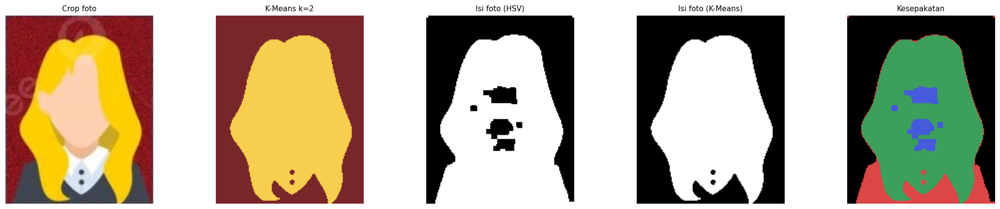

In [ ]:
foto_kmeans, label_foto, pusat_foto = segmentasi_kmeans(foto, 2)
selisih_merah = pusat_foto[:, 0].astype(int) - np.maximum(pusat_foto[:, 1], pusat_foto[:, 2]).astype(int)
klaster_latar = int(np.argmax(selisih_merah))

fg_kmeans = ((label_foto != klaster_latar) * 255).astype(np.uint8)
fg_hsv = ((merah_foto == 0) * 255).astype(np.uint8)
fg_hsv = cv2.morphologyEx(fg_hsv, cv2.MORPH_OPEN, np.ones((3, 3), np.uint8))

m = metrik_biner(fg_kmeans, fg_hsv)

print(f"Centroid cluster       : {[list(map(int, c)) for c in pusat_foto]}")
print(f"Cluster latar (merah)  : {klaster_latar}")
print(f"Porsi isi foto (HSV)   : {fg_hsv.mean() / 255 * 100:5.1f}%")
print(f"Porsi isi foto (KMeans): {fg_kmeans.mean() / 255 * 100:5.1f}%")
print(f"IoU HSV vs K-Means     : {m['IoU']:.3f}   Dice: {m['Dice']:.3f}")

selisih = np.zeros((*fg_hsv.shape, 3), np.uint8)
selisih[(fg_hsv > 0) & (fg_kmeans > 0)] = (60, 160, 90)
selisih[(fg_hsv > 0) & (fg_kmeans == 0)] = (220, 70, 70)
selisih[(fg_hsv == 0) & (fg_kmeans > 0)] = (70, 90, 220)

tampilkan(
    [foto, foto_kmeans, fg_hsv, fg_kmeans, selisih],
    ["Crop foto", "K-Means k=2", "Isi foto (HSV)", "Isi foto (K-Means)", "Kesepakatan"],
    ncols=5,
    skala=4.0,
)

Pada gambar **Kesepakatan**: hijau = kedua metode setuju (isi foto), merah = hanya HSV yang menganggap isi foto, biru = hanya K-Means yang menganggap isi foto.

### Analisis Tugas 2

1. **Segmentasi warna HSV berhasil mengekstrak pas foto KTP 2**, meskipun latar merah terpotong oleh rambut. Kunci keberhasilannya adalah urutan operasi: **mask warna → opening (buang noise) → closing (rapatkan celah) → kontur terbesar → crop**. Tanpa `closing`, kontur terbesar hanya menangkap sebagian area foto.

2. **`closing` memperbaiki kelengkapan objek, tetapi mengorbankan ketepatan batas.** Semakin besar kernel, semakin rapat mask, tetapi mask juga melebar ke luar bingkai sehingga `bounding box` sedikit lebih besar dari foto sebenarnya. Untuk keperluan *crop*, kelebihan beberapa piksel masih dapat diterima; untuk pengukuran luas, hal ini menjadi kesalahan sistematis.

3. **K-Means memberi hasil yang mirip tetapi tidak identik.** Nilai IoU sekitar 0,78 menunjukkan kedua pendekatan sepakat pada sebagian besar area isi foto. Perbedaannya terletak pada sifat metode: HSV memakai aturan warna yang eksplisit dan dapat diprediksi, sedangkan K-Means hanya mengelompokkan berdasarkan jarak ke centroid sehingga batas antara "merah tua" dan "rambut pirang" bisa bergeser bila `k` atau kondisi citra berubah. K-Means juga tidak memperhatikan keterhubungan spasial, jadi bercak kemerahan lain dapat masuk cluster latar.

4. **Perbandingan dengan KTP 1:** KTP 1 (bersih, rata) cukup diselesaikan dengan threshold global/Otsu. KTP 2 memerlukan pendekatan yang lebih tahan terhadap variasi, yaitu segmentasi warna + morfologi. Ini sesuai panduan pemilihan metode: **kenali kondisi citra lebih dulu, baru pilih algoritmanya**.

5. **Keterbatasan:** hasil crop masih menyertakan bingkai putih tipis di sekitar foto dan bagian rambut yang keluar dari bingkai. Perbaikan lanjutan bisa memakai *convex hull*, `minAreaRect`, atau deteksi tepi bingkai untuk mendapatkan batas foto yang lebih presisi.

---

# Kesimpulan Akhir

| Metode | Prinsip | Kekuatan | Kelemahan | Kapan dipakai |
|---|---|---|---|---|
| Global threshold | satu `T` untuk seluruh citra | sangat cepat, sederhana | sensitif `T` dan pencahayaan | citra rata, kontras tinggi |
| Otsu | `T` otomatis dari histogram | tanpa parameter, stabil pada bimodal | gagal bila kelas tidak seimbang / gradien kuat | scan dan foto dengan pencahayaan merata |
| Adaptive | `T` lokal per blok | tahan bayangan dan gradien | noise lokal ikut terangkat, perlu morfologi | pencahayaan tidak merata |
| Rentang warna HSV | ambang pada Hue/Saturation | langsung menyasar warna objek | perlu dua rentang Hue, sensitif tekstur | objek berwarna khas (pas foto, marka) |
| Region growing | tumbuh dari seed | hasil selalu terhubung, batas halus | sensitif seed dan ambang | objek homogen yang terhubung |
| Split & merge | quadtree + penggabungan | tanpa seed | batas berbentuk blok | analisis region kasar |
| Watershed + marker | topografi + marker | memisahkan objek bersentuhan | over-segmentation tanpa marker | objek bertumpuk (sel, koin) |
| K-Means | clustering vektor warna | tanpa aturan warna manual | jumlah `k` harus ditentukan, lambat | citra berwarna multi-objek |

**Pelajaran utama dari Pertemuan 7:**

1. Segmentasi bukan sekadar "satu baris `cv2.threshold`". Kualitasnya ditentukan oleh pemahaman histogram, kondisi pencahayaan, dan sifat objek.
2. Hasil segmentasi harus **diukur**, bukan hanya dilihat. IoU/Dice pada data ber-*ground truth* (sintetis atau semu) membuat perbandingan metode menjadi objektif.
3. Tidak ada metode yang selalu menang: pada KTP 1 Otsu sudah cukup, sedangkan KTP 2 menuntut segmentasi warna dan morfologi.
4. Segmentasi adalah tahap **awal**. Kesalahan di sini akan merambat ke ekstraksi fitur dan klasifikasi berikutnya, sehingga pembersihan morfologi dan validasi visual selalu diperlukan.